# Lab: avaliando um modelo de triagem de diabetes

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/classification-metrics/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar o alvo

**Preveja.** O conjunto reúne mulheres encaminhadas a um estudo sobre diabetes, não a população geral. Você espera que as duas classes estejam equilibradas? Um modelo que sempre responde "sem diabetes" acertaria mais ou menos que a metade das vezes?

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

pima = fetch_openml(data_id=37, as_frame=True)
X = pima.data.copy()                                       # 8 medidas por mulher
y = (pima.target == 'tested_positive').astype(int)         # 1 = diabetes, 0 = sem diabetes
print(X.shape)
print(y.value_counts())
print(f"prevalence: {y.mean():.3f}")

(768, 8)
class
0    500
1    268
Name: count, dtype: int64
prevalence: 0.349


**Resposta.** Não estão equilibradas: 268 das 768 mulheres têm diabetes (prevalência 0,349) e 500 não têm. Um modelo que sempre responde "sem diabetes" acertaria 500/768 = 65,1%, mais que a metade.

## Passo 2 — zeros que significam "não medido"

**Preveja.** A coluna de insulina tem centenas de zeros. Um zero de insulina é uma medida de verdade ou o código de "não medido"? Se ele ficasse como zero, o valor seria lido como uma medida muito baixa ou muito alta?

In [2]:
print((X == 0).sum().to_frame('zeros').T)

missing = ['plas', 'pres', 'skin', 'insu', 'mass']   # um zero aqui é impossível: "não medido"
X[missing] = X[missing].replace(0, np.nan)
print(f"rows with at least one missing value: {X.isna().any(axis=1).sum()}")

       preg  plas  pres  skin  insu  mass  pedi  age
zeros   111     5    35   227   374    11     0    0
rows with at least one missing value: 376


**Resposta.** É o código de "não medido": ninguém tem insulina, pressão, dobra cutânea ou IMC iguais a zero (já `preg = 0` é real, por isso fica). Se ficasse como zero, seria lido como uma medida absurdamente baixa; depois da troca por `NaN`, 376 das 768 linhas têm ao menos um valor faltante.

## Passo 3 — três divisões

**Preveja.** Para que serve cada uma das três partes? Qual delas pode ser olhada quantas vezes você quiser e qual só pode ser tocada uma vez?

In [3]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y,
                                                  random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25,
                                                  stratify=y_temp, random_state=42)
for name, part in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f"{name:10s} {len(part):3d} rows · {part.sum():3d} positive ({part.mean():.1%})")

train      460 rows · 160 positive (34.8%)
validation 154 rows ·  54 positive (35.1%)
test       154 rows ·  54 positive (35.1%)


**Resposta.** O treino (460 linhas) ajusta os parâmetros, a validação (154) compara modelos e escolhe o limiar e pode ser olhada quantas vezes quiser, e o teste (154) é tocado uma única vez no fim, para estimar o desempenho. A estratificação mantém os positivos entre 34,8% e 35,1% nas três partes.

## Passo 4 — dois modelos, duas matrizes de confusão

**Preveja.** Os dois modelos vão errar nas mesmas mulheres? Numa ferramenta de triagem, qual dos dois erros você preferiria evitar: mandar para casa uma mulher com diabetes ou encaminhar uma sem diabetes a um exame a mais?

logistic regression:
 [[32 22]
 [12 88]]
k-NN (k = 5):
 [[35 19]
 [13 87]]


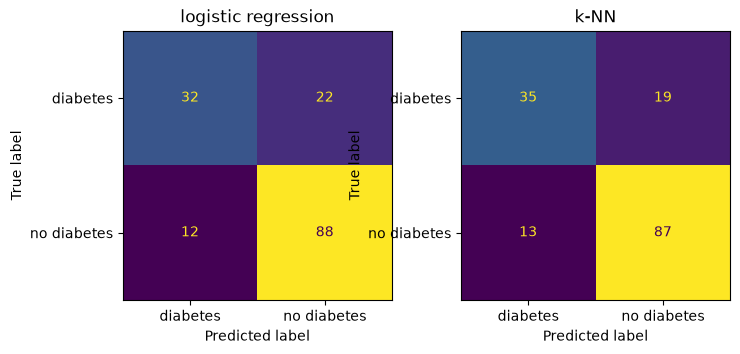

In [4]:
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logreg = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                       LogisticRegression(max_iter=1000)).fit(X_train, y_train)
knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                    KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

pred_lr, pred_knn = logreg.predict(X_val), knn.predict(X_val)
print("logistic regression:\n", confusion_matrix(y_val, pred_lr, labels=[1, 0]))
print("k-NN (k = 5):\n", confusion_matrix(y_val, pred_knn, labels=[1, 0]))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, pred, title in [(axes[0], pred_lr, 'logistic regression'), (axes[1], pred_knn, 'k-NN')]:
    ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=[1, 0],
                                            display_labels=['diabetes', 'no diabetes'], ax=ax, colorbar=False)
    ax.set_title(title)
plt.show()

**Resposta.** Não erram igual: a regressão logística deixa escapar 22 das 54 mulheres com diabetes e o k-NN 19, com 12 e 13 falsos alarmes. Numa triagem, o erro a evitar é mandar para casa uma mulher com diabetes (falso negativo); um exame a mais é barato.

## Passo 5 — as métricas à mão a partir do `.ravel()`

**Preveja.** A acurácia da regressão logística na validação vai ficar perto de 78%. Olhando só esse número, você diria que a ferramenta está pronta para ser usada? O que ele não conta?

In [5]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

tp, fn, fp, tn = confusion_matrix(y_val, pred_lr, labels=[1, 0]).ravel()
print(f"tp={tp} fn={fn} fp={fp} tn={tn}")
by_hand = {'accuracy':    (tp + tn) / (tp + tn + fp + fn),
           'precision':   tp / (tp + fp),
           'recall':      tp / (tp + fn),
           'specificity': tn / (tn + fp),
           'F1':          2 * tp / (2 * tp + fp + fn)}
library = {'accuracy':    accuracy_score(y_val, pred_lr),
           'precision':   precision_score(y_val, pred_lr),
           'recall':      recall_score(y_val, pred_lr),
           'specificity': recall_score(y_val, pred_lr, pos_label=0),
           'F1':          f1_score(y_val, pred_lr)}
for name in by_hand:
    print(f"{name:12s} by hand {by_hand[name]:.3f}   sklearn {library[name]:.3f}")

tp=32 fn=22 fp=12 tn=88
accuracy     by hand 0.779   sklearn 0.779
precision    by hand 0.727   sklearn 0.727
recall       by hand 0.593   sklearn 0.593
specificity  by hand 0.880   sklearn 0.880
F1           by hand 0.653   sklearn 0.653


**Resposta.** Não: os 77,9% escondem que a revocação é só 0,593, ou seja, 22 das 54 mulheres com diabetes escapam, e um modelo que nunca marca ninguém já chega a 64,9%. As contas à mão a partir de `tp=32 fn=22 fp=12 tn=88` batem com o sklearn.

**Simulação: de quem são os escapes?** A regressão logística em 0,5 deixa escapar 22 das 54 mulheres com diabetes. Pegue a probabilidade prevista de cada uma dessas 22 e veja onde esses escores caem: elas ficaram logo abaixo de 0,5, hesitando, ou bem mais longe? Se o limiar baixasse para 0,3, quantas seriam recuperadas?

In [6]:
proba_lr = logreg.predict_proba(X_val)[:, 1]
missed = proba_lr[(y_val.values == 1) & (pred_lr == 0)]    # mulheres com diabetes que escaparam
print(f"escapes: {len(missed)}   mean score {missed.mean():.3f}")
bins = pd.cut(pd.Series(missed), bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5])
print(bins.value_counts().sort_index().to_string())
print(f"recovered at threshold 0.3: {(missed >= 0.3).sum()} of {len(missed)}")

escapes: 22   mean score 0.273
(0.0, 0.1]    1
(0.1, 0.2]    5
(0.2, 0.3]    8
(0.3, 0.4]    4
(0.4, 0.5]    4
recovered at threshold 0.3: 8 of 22


**Leitura.** As 22 que escaparam têm escore médio 0,273. Só 4 ficaram entre 0,4 e 0,5, hesitando; 14 receberam menos de 0,3 (6 abaixo de 0,2), então o modelo está confiante e errado sobre elas. Baixar o limiar para 0,3 recupera 8 das 22; as outras 14 não se resolvem mexendo no limiar sem marcar muitas saudáveis.

## Passo 6 — `classification_report`

**Preveja.** O relatório imprime uma linha por classe. A linha `no diabetes` mede o quê, em palavras? (Dica: qual é a "revocação" da classe negativa?)

In [7]:
from sklearn.metrics import classification_report

print(classification_report(y_val, pred_lr, target_names=['no diabetes', 'diabetes'], digits=3))

              precision    recall  f1-score   support

 no diabetes      0.800     0.880     0.838       100
    diabetes      0.727     0.593     0.653        54

    accuracy                          0.779       154
   macro avg      0.764     0.736     0.746       154
weighted avg      0.774     0.779     0.773       154



**Resposta.** A linha `no diabetes` trata a classe negativa como positiva: a revocação 0,880 é a especificidade (88 das 100 sem diabetes foram mandadas para casa corretamente) e a precisão 0,800 é o valor preditivo negativo (das 110 classificadas como sem diabetes, 88 de fato não têm).

## Passo 7 — um placar com as baselines

**Preveja.** Entre a regressão logística e o k-NN, quem vence? Antes de olhar: vence em qual métrica? E quanto de acurácia um modelo que sempre responde "sem diabetes" consegue aqui?

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

def scores(y_true, y_pred):
    return {'accuracy':    accuracy_score(y_true, y_pred),
            'precision':   precision_score(y_true, y_pred, zero_division=0),
            'recall':      recall_score(y_true, y_pred),
            'specificity': recall_score(y_true, y_pred, pos_label=0),
            'F1':          f1_score(y_true, y_pred),
            'balanced':    balanced_accuracy_score(y_true, y_pred),
            'MCC':         matthews_corrcoef(y_true, y_pred)}

models = {'dummy majority':   DummyClassifier(strategy='most_frequent'),
          'dummy stratified': DummyClassifier(strategy='stratified', random_state=0),
          'logistic':         logreg,
          'k-NN':             knn}
board = pd.DataFrame({name: scores(y_val, m.fit(X_train, y_train).predict(X_val))
                      for name, m in models.items()}).T
print(board.round(3).to_string())

                  accuracy  precision  recall  specificity     F1  balanced    MCC
dummy majority       0.649      0.000   0.000         1.00  0.000     0.500  0.000
dummy stratified     0.513      0.302   0.296         0.63  0.299     0.463 -0.074
logistic             0.779      0.727   0.593         0.88  0.653     0.736  0.499
k-NN                 0.792      0.729   0.648         0.87  0.686     0.759  0.534

**Resposta.** No limiar padrão o k-NN vence a logística por pouco em quase tudo: acurácia 0,792 contra 0,779, revocação 0,648 contra 0,593, F1 0,686 contra 0,653 e MCC 0,534 contra 0,499; a logística só ganha em especificidade (0,88 contra 0,87). O modelo que sempre responde "sem diabetes" chega a 64,9% de acurácia com revocação zero.

**Simulação: e se o diabetes fosse raro?** O conjunto Pima tem 34,9% de prevalência, muito acima da população geral. Monte uma validação com as mesmas mulheres, mas com a doença rara: fique com as 100 sem diabetes e sorteie só 5 com diabetes. Refaça o placar nessa validação. Quem lidera a acurácia agora? A acurácia balanceada e o MCC mudam de opinião?

In [9]:
rng = np.random.default_rng(42)
pos_idx = rng.choice(y_val.index[y_val == 1], size=5, replace=False)
rare = y_val.index[y_val == 0].append(pd.Index(pos_idx))       # 100 sem diabetes + 5 com
X_rare, y_rare = X_val.loc[rare], y_val.loc[rare]
print(f"{len(y_rare)} women, {y_rare.sum()} with diabetes ({y_rare.mean():.1%})")

# os modelos já foram ajustados no passo 7: só muda a validação
board_rare = pd.DataFrame({name: scores(y_rare, m.predict(X_rare)) for name, m in models.items()}).T
print(board_rare.round(3).to_string())

105 women, 5 with diabetes (4.8%)
                  accuracy  precision  recall  specificity     F1  balanced    MCC
dummy majority       0.952      0.000     0.0         1.00  0.000     0.500  0.000
dummy stratified     0.686      0.088     0.6         0.69  0.154     0.645  0.132
logistic             0.876      0.250     0.8         0.88  0.381     0.840  0.403
k-NN                 0.867      0.235     0.8         0.87  0.364     0.835  0.387


**Leitura.** Com 5 doentes em 105 (4,8%), a baseline majoritária passa a liderar a acurácia (0,952), à frente da logística (0,876) e do k-NN (0,867): é o paradoxo da acurácia. A acurácia balanceada e o MCC não mudam de opinião: dão 0,500 e 0,000 à baseline e 0,840 e 0,403 à logística. A revocação 0,8 dos modelos são só 4 mulheres de 5, então qualquer número nesse cenário é muito ruidoso.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que 77,9% de acurácia não bastam para aprovar uma ferramenta de triagem? (2) Qual métrica lê a linha dos doentes e qual lê a coluna dos marcados? (3) O que acontece com as quatro contagens quando o limiar sobe?

**Resposta.**
1. Porque a revocação é 0,593: 22 das 54 mulheres com diabetes vão para casa, e não fazer nada já dá 64,9% de acurácia.
2. A revocação lê a linha dos doentes, TP/(TP+FN); a precisão lê a coluna dos marcados, TP/(TP+FP).
3. Quando o limiar sobe, TP e FP caem e FN e TN sobem (de 0,3 para 0,7: TP 40 → 24, FP 28 → 4, FN 14 → 30, TN 72 → 96).

## Sua vez (fundamental)

Para casa:

1. **Outra divisão.** Troque `random_state=42` no passo 3 por outros valores e refaça os passos 4 e 5. Quanto a revocação da regressão logística se mexe entre uma divisão e outra? Com 54 positivos na validação, quanto de revocação vale uma mulher?
2. **A outra classe.** No passo 5, calcule precisão e revocação com `pos_label=0`. Que métricas da tabela da seção 5 você obtém? Confira com a linha `no diabetes` do passo 6.
3. **Sem imputação.** Refaça o passo 4 mantendo os zeros originais (sem transformá-los em `NaN` e sem o `SimpleImputer`). A matriz de confusão muda? Por que tratar "não medido" como zero é pior que imputar a mediana?

## Passo 8 — avaliando as probabilidades

**Preveja.** Com k = 5, a "probabilidade" do k-NN é uma contagem de votos dividida por 5. Se uma mulher com diabetes tiver as cinco vizinhas mais próximas sem diabetes, que probabilidade ela recebe? O que uma resposta dessas faz com a log loss?

In [10]:
from sklearn.metrics import brier_score_loss, log_loss

prior = DummyClassifier(strategy='prior').fit(X_train, y_train)   # sempre responde 34,8%
for name, m in [('dummy prior', prior), ('logistic', logreg), ('k-NN', knn)]:
    p = m.predict_proba(X_val)[:, 1]
    print(f"{name:12s} log loss {log_loss(y_val, p):.3f}   Brier {brier_score_loss(y_val, p):.3f}")

votes = knn.predict_proba(X_val)[:, 1]          # fração dos 5 vizinhos com diabetes
print(pd.crosstab(votes, y_val, rownames=['k-NN probability'], colnames=['diabetes']))

dummy prior  log loss 0.648   Brier 0.228
logistic     log loss 0.452   Brier 0.148
k-NN         log loss 1.290   Brier 0.146
diabetes           0   1
k-NN probability        
0.0               51   3
0.2               25   7
0.4               11   9
0.6               11  18
0.8                1  13
1.0                1   4


**Resposta.** Ela recebe probabilidade 0, e a tabela mostra 3 mulheres com diabetes em 0,0 (e uma sem diabetes em 1,0). A log loss de um positivo com p = 0 seria infinita; o sklearn recorta p perto de 0, mas cada uma dessas 4 ainda soma cerca de 36/154 ≈ 0,23 à média, e por isso o k-NN tem log loss 1,290, pior que a baseline (0,648), mesmo com o melhor Brier (0,146).

**Simulação: um k maior conserta as probabilidades?** O problema do k-NN aqui é a granularidade grosseira dos votos: com k = 5 só existem seis probabilidades possíveis e duas delas são 0 e 1. Refaça a medida com k = 25 e k = 75, contando quantos valores distintos aparecem e quantas previsões saem exatamente em 0 ou 1. A log loss consegue descer abaixo da baseline? E o Brier, acompanha?

In [11]:
for k in [5, 25, 75]:
    knn_k = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                          KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    p = knn_k.predict_proba(X_val)[:, 1]
    print(f"k = {k:2d}   distinct {len(np.unique(p)):2d}   at 0 or 1 {np.isin(p, [0, 1]).sum():2d}"
          f"   log loss {log_loss(y_val, p):.3f}   Brier {brier_score_loss(y_val, p):.3f}")

k =  5   distinct  6   at 0 or 1 59   log loss 1.290   Brier 0.146
k = 25   distinct 21   at 0 or 1 10   log loss 0.443   Brier 0.147
k = 75   distinct 47   at 0 or 1  0   log loss 0.467   Brier 0.154


**Leitura.** Com k = 5 há 6 valores distintos e 59 previsões em 0 ou 1 (log loss 1,290); com k = 25 são 21 valores e só 10 nos extremos, e a log loss cai para 0,443, abaixo da baseline (0,648) e até da logística (0,452). Com k = 75 não sobra nenhum 0 ou 1, mas a log loss sobe um pouco (0,467), porque a média de 75 vizinhas fica vaga. O Brier quase não se mexe (0,146, 0,147, 0,154), já que cada erro custa no máximo 1: só a log loss denuncia o excesso de confiança.

## Passo 9 — mexendo no limiar, na validação

**Preveja.** Baixar o limiar de 0,5 para 0,3 encontra mais mulheres com diabetes. O que piora em troca? Você espera que o F1 registre bem essa troca?

In [12]:
from sklearn.metrics import fbeta_score

proba_val = logreg.predict_proba(X_val)[:, 1]
rows = []
for t in [0.3, 0.5, 0.7]:
    pred = (proba_val >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred, labels=[1, 0]).ravel()
    rows.append({'threshold': t, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                 'precision': precision_score(y_val, pred), 'recall': recall_score(y_val, pred),
                 'F1': f1_score(y_val, pred), 'F2': fbeta_score(y_val, pred, beta=2)})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
best_t = table.loc[table['F2'].idxmax(), 'threshold']
print(f"highest F2 on validation: threshold {best_t}")

 threshold  TP  FP  FN  TN  precision  recall    F1    F2
       0.3  40  28  14  72      0.588   0.741 0.656 0.704
       0.5  32  12  22  88      0.727   0.593 0.653 0.615
       0.7  24   4  30  96      0.857   0.444 0.585 0.492


highest F2 on validation: threshold 0.3


**Resposta.** Piora a precisão (0,727 → 0,588): os falsos alarmes mais que dobram (12 → 28) para encontrar 8 mulheres a mais (TP 32 → 40). O F1 quase não registra a troca (0,653 → 0,656); o F2, que pesa mais a revocação, sobe de 0,615 para 0,704.

**Simulação: o β escolhe o limiar.** O passo 9 comparou três limiares escolhidos à mão. Varra o limiar de 0,10 a 0,90, de 0,05 em 0,05 e encontre o limiar que maximiza cada um de F0,5, F1 e F2 na validação. Quantos escapes e quantos alarmes falsos cada escolha produz?

In [13]:
rows = []
for t in np.round(np.arange(0.10, 0.91, 0.05), 2):
    pred = (proba_val >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred, labels=[1, 0]).ravel()
    rows.append({'threshold': t, 'FN': fn, 'FP': fp,
                 'F0.5': fbeta_score(y_val, pred, beta=0.5, zero_division=0),
                 'F1': f1_score(y_val, pred, zero_division=0),
                 'F2': fbeta_score(y_val, pred, beta=2, zero_division=0)})
sweep = pd.DataFrame(rows)
for metric in ['F0.5', 'F1', 'F2']:
    row = sweep.loc[sweep[metric].idxmax()]
    print(f"{metric:4s} best threshold {row['threshold']:.2f}   escapes {int(row['FN']):2d}"
          f"   false alarms {int(row['FP']):2d}   score {row[metric]:.3f}")

F0.5 best threshold 0.60   escapes 25   false alarms  7   score 0.732


F1   best threshold 0.25   escapes 10   false alarms 30   score 0.688
F2   best threshold 0.10   escapes  1   false alarms 64   score 0.796


**Leitura.** O F0,5 escolhe 0,60 (25 escapes, 7 alarmes falsos), o F1 escolhe 0,25 (10 e 30) e o F2 desce até 0,10 (1 escape, mas 64 das 100 saudáveis encaminhadas). Quem escolhe a troca é o β, não os dados. O F2 para na borda da grade: sem uma restrição operacional, como a capacidade do laboratório, ele mandaria quase todas para o exame.

## Passo 10 — o único teste

**Preveja.** O limiar 0,3 foi escolhido na validação. No teste, você espera um resultado parecido, melhor ou pior? E a acurácia no teste vai ser maior ou menor que a do limiar 0,5 do passo 5?

In [14]:
pred_test = (logreg.predict_proba(X_test)[:, 1] >= best_t).astype(int)
print(confusion_matrix(y_test, pred_test, labels=[1, 0]))
final = scores(y_test, pred_test)
final['F2'] = fbeta_score(y_test, pred_test, beta=2)
print(pd.Series(final).round(3).to_string())

[[43 11]
 [28 72]]
accuracy       0.747
precision      0.606
recall         0.796
specificity    0.720
F1             0.688
balanced       0.758
MCC            0.494
F2             0.749


**Resposta.** Parecido: no teste o limiar 0,3 dá revocação 0,796 (43 de 54) e precisão 0,606, próximo da validação (0,741 e 0,588), um pouco melhor por ruído de 54 casos. A acurácia cai para 0,747, abaixo dos 0,779 do limiar 0,5, porque trocamos escapes por 28 alarmes falsos.

## Passo 11 — multiclasse: quais dígitos se confundem?

**Preveja.** Em dígitos manuscritos, que pares você espera ver confundidos? Com dez classes de tamanho quase igual, os F1 macro, ponderado e micro vão diferir muito?

[[54  0  0  0  0  0  0  0  0  0]
 [ 0 52  0  0  1  0  0  0  2  0]
 [ 0  0 53  0  0  0  0  0  0  0]
 [ 0  0  0 55  0  0  0  0  0  0]
 [ 0  0  0  0 53  0  0  0  1  0]
 [ 0  0  0  0  0 54  0  0  0  1]
 [ 0  0  0  0  0  0 53  0  1  0]
 [ 0  0  0  0  0  0  0 54  0  0]
 [ 0  3  0  0  0  0  0  0 49  0]
 [ 0  0  0  0  0  0  0  0  1 53]]


true 1 predicted as 8: 2 times
true 8 predicted as 1: 3 times
lowest recall: digit 8
macro    F1 0.9814
weighted F1 0.9816
micro    F1 0.9815
accuracy    0.9815


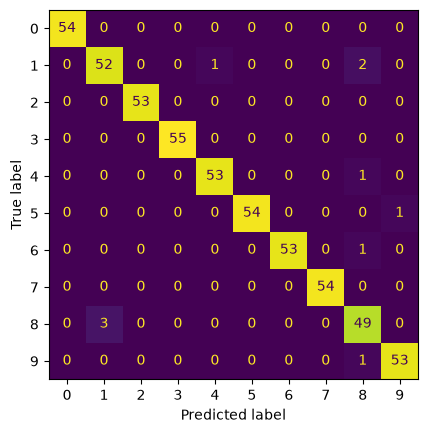

In [15]:
from sklearn.datasets import load_digits

Xd, yd = load_digits(return_X_y=True)                     # imagens 8x8 dos dígitos 0-9
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, stratify=yd,
                                                        random_state=42)
digits = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xd_train, yd_train)
pred_d = digits.predict(Xd_test)

cm = confusion_matrix(yd_test, pred_d)
print(cm)
off = cm.copy()
np.fill_diagonal(off, 0)                                  # fica só com os erros
for i, j in zip(*np.nonzero(off >= 2)):
    print(f"true {i} predicted as {j}: {off[i, j]} times")
print(f"lowest recall: digit {np.argmin(recall_score(yd_test, pred_d, average=None))}")
for avg in ['macro', 'weighted', 'micro']:
    print(f"{avg:8s} F1 {f1_score(yd_test, pred_d, average=avg):.4f}")
print(f"accuracy    {accuracy_score(yd_test, pred_d):.4f}")
ConfusionMatrixDisplay.from_predictions(yd_test, pred_d, colorbar=False)
plt.show()

**Resposta.** O par confundido é 8 ↔ 1 (3 oitos lidos como 1 e 2 uns lidos como 8), e o 8 tem a menor revocação. Com dez classes quase do mesmo tamanho, os F1 macro (0,9814), ponderado (0,9816) e micro (0,9815, igual à acurácia) praticamente coincidem.

**Para fechar a aula.** Em uma frase cada: (1) por que o k-NN com k = 5 ficou pior que a baseline na log loss, mesmo ganhando em F1? (2) Por que uma precisão medida neste conjunto não vale na população geral? (3) Em que situação o F1 macro e o ponderado discordam?

**Resposta.**
1. Com k = 5, 59 das 154 probabilidades saem exatamente em 0 ou 1, e a log loss pune sem teto os erros confiantes (4 deles bastam para levá-la a 1,290, acima dos 0,648 da baseline), enquanto o F1 só olha de que lado do limiar cada mulher caiu.
2. A precisão depende da prevalência: aqui 34,9% têm diabetes, e numa população com doença rara os mesmos acertos produzem muito mais falsos positivos por verdadeiro (na simulação com 4,8%, a precisão da logística caiu de 0,727 para 0,250).
3. Quando as classes têm tamanhos diferentes e a classe pequena é a pior: o macro dá a ela o mesmo peso das outras e cai, o ponderado a dilui (no exercício 4 avançado, macro 0,9788 contra ponderado 0,9877).

## Sua vez (avançado)

Para casa, com mais tempo:

1. **O outro modelo.** Repita o passo 9 com `knn` no lugar de `logreg`. Quais dos limiares 0,3, 0,5 e 0,7 dão matrizes de confusão diferentes e por quê? (Dica: que valores uma probabilidade de 5 votos pode assumir?)
2. **Limiar com restrição.** Varra o limiar de 0,10 a 0,90 na validação, faça o gráfico de precisão e revocação em função do limiar e encontre o menor limiar com precisão ≥ 0,6. Que revocação você obtém? Compare com o limiar que o F2 escolheu na simulação do passo 9.
3. **Pesos de classe.** Ajuste `LogisticRegression(max_iter=1000, class_weight='balanced')` no pipeline e refaça os passos 5 e 7 com limiar 0,5. Compare com o modelo sem pesos no limiar 0,3. As duas maneiras de trocar precisão por revocação são muito diferentes?
4. **Uma classe rara.** No passo 11, descarte 90% das imagens de treino *e* de teste do dígito 8 (fique com 10%), reajuste e compare de novo os F1 macro e ponderado. Qual deles se mexe e por quê?

## Sua vez (fundamental) — exercícios

### Sua vez — exercício 1 (fundamental): outra divisão

In [16]:
rows = []
for seed in [42, 0, 1, 2, 3, 4, 5, 6, 7, 8]:
    Xt, _, yt, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)   # o teste fica de lado
    Xtr, Xv, ytr, yv = train_test_split(Xt, yt, test_size=0.25, stratify=yt, random_state=seed)
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    tp, fn, fp, tn = confusion_matrix(yv, m.predict(Xv), labels=[1, 0]).ravel()
    rows.append({'seed': seed, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
                 'accuracy': (tp + tn) / len(yv), 'recall': tp / (tp + fn)})
splits = pd.DataFrame(rows)
print(splits.round(3).to_string(index=False))
print(f"recall: min {splits['recall'].min():.3f}   max {splits['recall'].max():.3f}"
      f"   std {splits['recall'].std():.3f}")
print(f"one woman is worth {1 / 54:.3f} of recall")

 seed  TP  FN  FP  TN  accuracy  recall
   42  32  22  12  88     0.779   0.593
    0  26  28  11  89     0.747   0.481
    1  31  23  17  83     0.740   0.574
    2  34  20  19  81     0.747   0.630
    3  27  27   8  92     0.773   0.500
    4  31  23  19  81     0.727   0.574
    5  30  24   7  93     0.799   0.556
    6  30  24  17  83     0.734   0.556
    7  28  26  17  83     0.721   0.519
    8  31  23   8  92     0.799   0.574
recall: min 0.481   max 0.630   std 0.045
one woman is worth 0.019 of recall


**Conclusão.** Em 10 divisões a revocação da logística na validação vai de 0,481 (seed 0) a 0,630 (seed 2), com desvio-padrão 0,045; a acurácia vai de 0,721 a 0,799. Uma mulher vale 1/54 = 0,019 de revocação, então essa faixa equivale a 8 mulheres, e diferenças de 2 a 3 pontos entre modelos (como logística contra k-NN no passo 7) estão dentro do ruído da divisão.

### Sua vez — exercício 2 (fundamental): a outra classe

In [17]:
tp, fn, fp, tn = confusion_matrix(y_val, pred_lr, labels=[1, 0]).ravel()
print(f"precision (pos_label=0) {precision_score(y_val, pred_lr, pos_label=0):.3f}"
      f"   = tn / (tn + fn) = {tn / (tn + fn):.3f}  (valor preditivo negativo)")
print(f"recall    (pos_label=0) {recall_score(y_val, pred_lr, pos_label=0):.3f}"
      f"   = tn / (tn + fp) = {tn / (tn + fp):.3f}  (especificidade)")

precision (pos_label=0) 0.800   = tn / (tn + fn) = 0.800  (valor preditivo negativo)
recall    (pos_label=0) 0.880   = tn / (tn + fp) = 0.880  (especificidade)


**Conclusão.** Com `pos_label=0`, a precisão vira o valor preditivo negativo, TN/(TN+FN) = 88/110 = 0,800, e a revocação vira a especificidade, TN/(TN+FP) = 88/100 = 0,880. Os dois números são exatamente os da linha `no diabetes` do `classification_report` do passo 6.

### Sua vez — exercício 3 (fundamental): sem imputação

In [18]:
X_raw = pima.data                                     # zeros originais, sem NaN
Xr_tr, Xr_val = X_raw.loc[X_train.index], X_raw.loc[X_val.index]
raw_models = {'logistic regression': (LogisticRegression(max_iter=1000), pred_lr),
              'k-NN (k = 5)': (KNeighborsClassifier(n_neighbors=5), pred_knn)}
for name, (clf, pred_imp) in raw_models.items():
    pred_raw = make_pipeline(StandardScaler(), clf).fit(Xr_tr, y_train).predict(Xr_val)
    print(f"{name}, zeros kept (median imputation was {confusion_matrix(y_val, pred_imp, labels=[1, 0]).tolist()}):")
    print(confusion_matrix(y_val, pred_raw, labels=[1, 0]))
    print(f"  recall {recall_score(y_val, pred_imp):.3f} -> {recall_score(y_val, pred_raw):.3f}   "
          f"accuracy {accuracy_score(y_val, pred_imp):.3f} -> {accuracy_score(y_val, pred_raw):.3f}   "
          f"predictions that changed: {(pred_raw != pred_imp).sum()}")
print(f"insulin in train: {(Xr_tr['insu'] == 0).mean():.1%} zeros; mean with zeros {Xr_tr['insu'].mean():.0f}"
      f", median of measured values {X_train['insu'].median():.0f}")

logistic regression, zeros kept (median imputation was [[32, 22], [12, 88]]):
[[33 21]
 [10 90]]
  recall 0.593 -> 0.611   accuracy 0.779 -> 0.799   predictions that changed: 7
k-NN (k = 5), zeros kept (median imputation was [[35, 19], [13, 87]]):
[[29 25]
 [17 83]]
  recall 0.648 -> 0.537   accuracy 0.792 -> 0.727   predictions that changed: 18
insulin in train: 46.7% zeros; mean with zeros 79, median of measured values 125


**Conclusão.** A matriz muda. Na logística, nesta divisão, quase nada (7 previsões mudam, revocação 0,593 → 0,611): um modelo linear consegue compensar parte do artefato, e o fato de não ter sido medido pode até carregar alguma informação. No k-NN o estrago é claro: revocação 0,648 → 0,537, acurácia 0,792 → 0,727 e 18 previsões trocadas. Tratar "não medido" como zero é pior porque o zero é lido como uma medida real e extrema (46,7% de zeros de insulina no treino puxam a média para 79, contra 125 de mediana entre as medidas): distorce o escalonamento e as distâncias e aproxima mulheres só por não terem feito o exame. A mediana põe o valor faltante no meio da distribuição, sem inventar um extremo.

## Sua vez (avançado) — exercícios

### Sua vez — exercício 1 (avançado): o outro modelo

In [19]:
proba_knn = knn.predict_proba(X_val)[:, 1]
print("possible k-NN probabilities:", np.unique(proba_knn))
for t in [0.25, 0.3, 0.35, 0.5, 0.55, 0.7, 0.75]:
    pred = (proba_knn >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred, labels=[1, 0]).ravel()
    print(f"threshold {t:.2f}   TP {tp:2d}   FP {fp:2d}   FN {fn:2d}   TN {tn:3d}   "
          f"precision {precision_score(y_val, pred):.3f}   recall {recall_score(y_val, pred):.3f}")

possible k-NN probabilities: [0.  0.2 0.4 0.6 0.8 1. ]
threshold 0.25   TP 44   FP 24   FN 10   TN  76   precision 0.647   recall 0.815
threshold 0.30   TP 44   FP 24   FN 10   TN  76   precision 0.647   recall 0.815
threshold 0.35   TP 44   FP 24   FN 10   TN  76   precision 0.647   recall 0.815
threshold 0.50   TP 35   FP 13   FN 19   TN  87   precision 0.729   recall 0.648
threshold 0.55   TP 35   FP 13   FN 19   TN  87   precision 0.729   recall 0.648
threshold 0.70   TP 17   FP  2   FN 37   TN  98   precision 0.895   recall 0.315
threshold 0.75   TP 17   FP  2   FN 37   TN  98   precision 0.895   recall 0.315


**Conclusão.** As três matrizes são diferentes: 0,3 dá 44 TP e 24 FP (revocação 0,815), 0,5 dá 35 e 13 (igual ao `predict` do passo 4) e 0,7 dá 17 e 2. Isso acontece porque a probabilidade de 5 votos só assume 0; 0,2; 0,4; 0,6; 0,8; 1, e 0,3, 0,5 e 0,7 caem em intervalos diferentes entre esses valores. Qualquer limiar dentro do mesmo intervalo dá a mesma matriz (0,25 e 0,35 iguais a 0,3; 0,55 igual a 0,5; 0,75 igual a 0,7): o k-NN só oferece 7 pontos de operação.

### Sua vez — exercício 2 (avançado): limiar com restrição

smallest threshold with precision >= 0.6: 0.32   precision 0.613   recall 0.704
threshold chosen by F2: 0.10   precision 0.453   recall 0.981


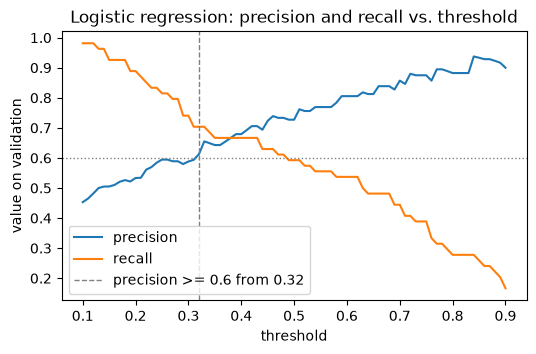

In [20]:
grid = np.round(np.arange(0.10, 0.901, 0.01), 2)
curve = pd.DataFrame({'threshold': grid,
                      'precision': [precision_score(y_val, proba_val >= t, zero_division=0) for t in grid],
                      'recall': [recall_score(y_val, proba_val >= t) for t in grid]})
first = curve[curve['precision'] >= 0.6].iloc[0]
f2_t = sweep.loc[sweep['F2'].idxmax(), 'threshold']
f2_row = curve[np.isclose(curve['threshold'], f2_t)].iloc[0]
print(f"smallest threshold with precision >= 0.6: {first['threshold']:.2f}   "
      f"precision {first['precision']:.3f}   recall {first['recall']:.3f}")
print(f"threshold chosen by F2: {f2_t:.2f}   precision {f2_row['precision']:.3f}   recall {f2_row['recall']:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(curve['threshold'], curve['precision'], label='precision')
ax.plot(curve['threshold'], curve['recall'], label='recall')
ax.axhline(0.6, color='gray', ls=':', lw=1)
ax.axvline(first['threshold'], color='gray', ls='--', lw=1, label=f"precision >= 0.6 from {first['threshold']:.2f}")
ax.set_xlabel('threshold')
ax.set_ylabel('value on validation')
ax.set_title('Logistic regression: precision and recall vs. threshold')
ax.legend()
plt.show()

**Conclusão.** O menor limiar com precisão ≥ 0,6 é 0,32, com precisão 0,613 e revocação 0,704 (38 das 54). O F2 da simulação escolheu 0,10, com revocação 0,981 mas precisão 0,453. A restrição de precisão custa 28 pontos de revocação (cerca de 15 mulheres) em troca de bem menos alarmes falsos: são pontos diferentes da mesma curva, e a escolha é operacional.

### Sua vez — exercício 3 (avançado): pesos de classe

In [21]:
logreg_w = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight='balanced')).fit(X_train, y_train)
pred_w = logreg_w.predict(X_val)
pred_03 = (proba_val >= 0.3).astype(int)
print("balanced weights, threshold 0.5:\n", confusion_matrix(y_val, pred_w, labels=[1, 0]))
print("no weights, threshold 0.3:\n", confusion_matrix(y_val, pred_03, labels=[1, 0]))
compare = pd.DataFrame({'no weights @ 0.5': scores(y_val, pred_lr),
                        'balanced @ 0.5': scores(y_val, pred_w),
                        'no weights @ 0.3': scores(y_val, pred_03)}).T
print(compare.round(3).to_string())
print(f"women classified differently by the two 'recall' rules: {(pred_w != pred_03).sum()} of {len(y_val)}")

balanced weights, threshold 0.5:
 [[37 17]
 [21 79]]
no weights, threshold 0.3:
 [[40 14]
 [28 72]]
                  accuracy  precision  recall  specificity     F1  balanced    MCC
no weights @ 0.5     0.779      0.727   0.593         0.88  0.653     0.736  0.499
balanced @ 0.5       0.753      0.638   0.685         0.79  0.661     0.738  0.468
no weights @ 0.3     0.727      0.588   0.741         0.72  0.656     0.730  0.443
women classified differently by the two 'recall' rules: 10 of 154


**Conclusão.** Com pesos e limiar 0,5, o modelo encontra 37 das 54 (revocação 0,685, precisão 0,638); sem pesos em 0,3, encontra 40 (revocação 0,741, precisão 0,588). A acurácia balanceada (0,738 contra 0,730) e o F1 (0,661 contra 0,656) são quase iguais, e as duas regras discordam em só 10 de 154 mulheres. Não são muito diferentes: os pesos apenas deslocam o ponto de operação, como baixar o limiar para algo entre 0,3 e 0,5; mexer no limiar é mais barato (sem retreinar) e mais fácil de ajustar.

### Sua vez — exercício 4 (avançado): uma classe rara

In [22]:
rng = np.random.default_rng(42)

def keep_10pct_of_eights(Xa, ya):
    eights = np.flatnonzero(ya == 8)
    drop = rng.choice(eights, size=round(0.9 * len(eights)), replace=False)
    keep = np.setdiff1d(np.arange(len(ya)), drop)
    return Xa[keep], ya[keep]

Xr_train, yr_train = keep_10pct_of_eights(Xd_train, yd_train)
Xr_test, yr_test = keep_10pct_of_eights(Xd_test, yd_test)
print(f"8s in train: {(yr_train == 8).sum()}   8s in test: {(yr_test == 8).sum()}")
digits_r = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xr_train, yr_train)
pred_r = digits_r.predict(Xr_test)
print(f"F1 of digit 8: before {f1_score(yd_test, pred_d, average=None)[8]:.3f}"
      f"   after {f1_score(yr_test, pred_r, average=None)[8]:.3f}")
for avg in ['macro', 'weighted']:
    print(f"{avg:8s} F1   before {f1_score(yd_test, pred_d, average=avg):.4f}"
          f"   after {f1_score(yr_test, pred_r, average=avg):.4f}")

8s in train: 12   8s in test: 5
F1 of digit 8: before 0.925   after 0.889
macro    F1   before 0.9814   after 0.9788
weighted F1   before 0.9816   after 0.9877


**Conclusão.** Ficando com 12 oitos no treino e 5 no teste, o F1 do dígito 8 cai de 0,925 para 0,889. O F1 macro cai (0,9814 → 0,9788), porque dá ao 8 o mesmo peso de 1/10 das outras classes, enquanto o ponderado sobe (0,9816 → 0,9877), porque o 8 passa a pesar cerca de 1% e a remoção de 47 oitos tirou do teste a classe com mais erros. O macro é o que revela a classe rara mal resolvida.